Base class for all layers (Hidden layers and Activation layers).

We can forward or backward propagate at each layer.

In [ ]:
import numpy as np
from abc import ABC, abstractmethod


class Layer(ABC):
    @abstractmethod
    def forward_propagate(self, input):
        pass

    @abstractmethod
    def backward_propagate(self, input, grad_output):
        pass

Hidden layer class

In [ ]:
np.random.seed(0)


class HiddenLayer(Layer):
    def __init__(self, input_units, output_units, learning_rate=0.1):

        self.learning_rate = learning_rate
        self.weights = np.random.normal(
            loc=0.0,
            scale=np.sqrt(2 / (input_units + output_units)),
            size=(input_units, output_units),
        )
        self.biases = np.zeros(output_units)

    def forward_propagate(self, input):
        return np.dot(input, self.weights) + self.biases

    def backward_propagate(self, input, grad_output):
        grad_input = np.dot(grad_output, self.weights.T)

        grad_weights = np.dot(input.T, grad_output)
        grad_biases = grad_output.mean(axis=0) * input.shape[0]

        assert (
            grad_weights.shape == self.weights.shape
            and grad_biases.shape == self.biases.shape
        )

        self.weights = self.weights - self.learning_rate * grad_weights
        self.biases = self.biases - self.learning_rate * grad_biases

        return grad_input

Activation functions

In [ ]:
class Activation(Layer):
    pass


class LeakyRelu(Activation):
    """Based on this answer on stackoverflow:
    https://stackoverflow.com/questions/50517545/how-do-i-implement-leaky-relu-using-numpy-functions#comment97538129_54206300"""

    def __init__(self, a=0.01):
        self.a = a

    def forward_propagate(self, input):
        return np.where(input > 0, input, input * self.a)

    def backward_propagate(self, input, grad_output):
        gradient = np.where(input > 0, 1.0, self.a)
        return grad_output * gradient


class Tanh(Activation):
    def forward_propagate(self, input):
        return np.tanh(input)

    def backward_propagate(self, input, grad_output):
        gradient = 1.0 - self.forward_propagate(input) * self.forward_propagate(input)
        return grad_output * gradient


class Sig(Activation):
    def forward_propagate(self, input):
        return 1 / (1 + np.exp(-input))

    def backward_propagate(self, input, grad_output):
        gradient = self.forward_propagate(input) * (1.0 - self.forward_propagate(input))
        return grad_output * gradient


class ReLU(Activation):
    def forward_propagate(self, input):
        relu_forward_propagate = np.maximum(0, input)
        return relu_forward_propagate

    def backward_propagate(self, input, grad_output):
        relu_grad = input > 0
        return grad_output * relu_grad

Loss functions. We use softmax cross entropy.

In [ ]:
def softmax_crossentropy_with_logits(logits, reference_answers):
    logits_for_answers = logits[np.arange(len(logits)), reference_answers]

    xentropy = -logits_for_answers + np.log(np.sum(np.exp(logits), axis=-1))

    return xentropy


def grad_softmax_crossentropy_with_logits(logits, reference_answers):
    ones_for_answers = np.zeros_like(logits)
    ones_for_answers[np.arange(len(logits)), reference_answers] = 1

    softmax = np.exp(logits) / np.exp(logits).sum(axis=-1, keepdims=True)

    return (-ones_for_answers + softmax) / logits.shape[0]

MLP class

In [ ]:
from time import time
from tqdm.autonotebook import tqdm, trange


class MLP:
    def __init__(self, activation, num_in, hidden, lr=0.1, num_out=10):
        network = []

        # no hidden layers
        if len(hidden) == 0:
            network.append(HiddenLayer(num_in, num_out, learning_rate=lr))

        for index, layer in enumerate(hidden):

            # input layer
            if index == 0:
                network.append(HiddenLayer(num_in, layer, learning_rate=lr))
                network.append(activation())

            # deep layer
            if index != len(hidden) - 1:
                network.append(HiddenLayer(layer, hidden[index + 1], learning_rate=lr))
                network.append(activation())
            else:
                # output layer
                network.append(HiddenLayer(layer, num_out, learning_rate=lr))

        self.network = network

    def forward_propagate(self, X):
        activations = []
        input = X

        # Looping through each layer
        for l in self.network:
            activations.append(l.forward_propagate(input))
            # Updating input to last layer output
            input = activations[-1]

        assert len(activations) == len(self.network)
        return activations

    def fit(
        self, X, y, epoch_num, batchsize, X_test=None, y_test=None, show_progress=False
    ):
        start_time = time()
        for epoch in trange(epoch_num):
            for x_batch, y_batch in self.iterate_minibatches(
                X, y, batchsize=batchsize, shuffle=True
            ):
                self._fit(x_batch, y_batch)
            if show_progress:
                ex_time = time() - start_time
                yield self.evaluate_acc(
                    y_test, self.predict(X_test)
                ), self.evaluate_acc(y, self.predict(X)), ex_time

    def _fit(self, X, y):

        # Get the layer activations
        layer_activations = self.forward_propagate(X)
        layer_inputs = [
            X
        ] + layer_activations  # layer_input[i] is an input for network[i]
        logits = layer_activations[-1]

        # Compute the loss and the initial gradient
        loss = softmax_crossentropy_with_logits(logits, y)
        loss_grad = grad_softmax_crossentropy_with_logits(logits, y)

        # Propagate gradients through the network
        # Reverse propogation as this is backprop
        for layer_index in range(len(self.network))[::-1]:
            layer = self.network[layer_index]

            loss_grad = layer.backward_propagate(
                layer_inputs[layer_index], loss_grad
            )  # grad w.r.t. input, also weight updates

        return np.mean(loss)

    def predict(self, X):

        logits = self.forward_propagate(X)[-1]
        return logits.argmax(axis=-1)

    @staticmethod
    def iterate_minibatches(inputs, targets, batchsize, shuffle=False):
        assert len(inputs) == len(targets)
        if shuffle:
            indices = np.random.permutation(len(inputs))
        for start_idx in range(0, len(inputs) - batchsize + 1, batchsize):
            if shuffle:
                excerpt = indices[start_idx : start_idx + batchsize]
            else:
                excerpt = slice(start_idx, start_idx + batchsize)
            yield inputs[excerpt], targets[excerpt]

    @staticmethod
    def evaluate_acc(true_labels, target_labels):
        """Evaluate the model accuracy""" ""
        return np.mean(true_labels == target_labels)

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  


Preprocessing class

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.linalg import eigh
import pandas as pd


class preprocessing:
    def __init__(
        self, dataset, symetric_dataset, dimension_reduction, data_whitening, normalize
    ):
        """acquire data """
        self.dataset = dataset
        self.x_train_arr = []
        self.x_test_arr = []
        self.symetric = symetric_dataset
        self.dim_reduct = dimension_reduction
        self.data_whitening = data_whitening
        self.normalize = normalize

    def preprocess_mnist(self):
        print("Preprocessing the MNIST dataset...\n")

        (x_train, y_train), (x_test, y_test) = self.dataset
        self.x_train_arr = self.flatten_maker(x_train)
        self.x_test_arr = self.flatten_maker(x_test)

        if not (self.symetric):
            self.x_train_arr = self.pixel_remover(self.x_train_arr)
            self.x_test_arr = self.pixel_remover(self.x_test_arr)

        """Mean subtraction"""
        self.x_train_arr = self.mean_subtractor(self.x_train_arr)
        self.x_test_arr = self.mean_subtractor(self.x_test_arr)

        if self.normalize:
            """Normalization"""
            self.x_train_arr = self.normalizer(self.x_train_arr)
            self.x_test_arr = self.normalizer(self.x_test_arr)

        """Dimensionality reduction"""
        if self.dim_reduct:
            cov_matrix = (
                np.matmul(self.x_train_arr.T, self.x_train_arr)
                / self.x_train_arr.shape[0]
            )
            U, S, V = np.linalg.svd(cov_matrix)
            Xrot = np.dot(self.x_train_arr, U)
            Xrot_reduced = np.dot(self.x_train_arr, U[:, :100])

        """Data Whitening"""
        if self.data_whitening:
            Xwhite = Xrot / np.sqrt(S + 1e-5)

        return self.x_train_arr, y_train, self.x_test_arr, y_test

    def flatten_maker(self, input_data):
        """flattening data so that
        returns N * D array"""
        output_data = []
        i = 0
        while i < len(input_data):
            output_data.append(np.array(input_data[i]).flatten())
            i += 1
        return np.array(output_data)

    def mean_subtractor(self, input_data):
        """Mean subtraction is done to
        obtain zero-centered data"""
        data = input_data.astype("float32")
        output_data = data - np.mean(data)
        return output_data

    def normalizer(self, nonNorm_data):
        """Normalization through dividing into the
        standard deviation of each dimension (row)"""
        std_dev = np.std(nonNorm_data, axis=1)
        norm_data = nonNorm_data / std_dev[:, None]
        return norm_data

    def pixel_remover(self, data):
        """removing always black (0)
        pixels -where all the numpy
        columns are zero"""
        idx = np.argwhere(np.all(data[..., :] == 0, axis=0))
        output = np.delete(data, idx, axis=1)
        print("Index of removed columns/pixels are " + str(np.array(idx).flatten()))
        return output

Helper class for plotting and visualizing results

In [41]:
import seaborn as sns
from sklearn.metrics import confusion_matrix


class visualization:
    def __init__(self, x_train, y_train, x_test, y_test):
        self.x_train = x_train
        self.y_train = y_train
        self.x_test = x_test
        self.y_test = y_test

    def image_show(self):
        plt.imshow(self.x_train[0, :, :, 0])
        plt.colorbar()
        plt.show()

    def digits_distribution(self):
        x = [{i: np.random.randint(1, 5)} for i in range(10)]
        my_colors = [(x / 10.0, x / 20.0, 0.75) for x in range(10)]
        _ = (
            pd.DataFrame(self.y_train)
            .value_counts()
            .plot(kind="bar", stacked=True, color=my_colors)
        )
        plt.show()


def plot_epoch_accuracy(accuracies_test, accuracies_train, durations, epoch_num):
    fig = plt.figure()
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()
    fig.subplots_adjust(bottom=0.2)
    ticks = range(1, epoch_num + 1, 5)
    ax1.plot(range(1, epoch_num + 1), accuracies_test, label="test accuracy")
    ax1.plot(range(1, epoch_num + 1), accuracies_train, label="train accuracy")
    ax1.set_xticks(ticks)
    ax1.set_xlabel("epoch")
    ax2.xaxis.set_ticks_position("bottom")
    ax2.xaxis.set_label_position("bottom")
    ax2.spines["bottom"].set_position(("axes", -0.2))
    ax2.set_frame_on(True)
    ax2.patch.set_visible(False)
    for sp in ax2.spines.values():
        sp.set_visible(False)
    ax2.spines["bottom"].set_visible(True)
    ax2.set_xlabel("duration")
    ax2.set_xticks(ticks)
    ax2.set_xticklabels(durations[::5])
    plt.xticks(ticks)
    ax1.grid(True)
    ax1.legend()
    plt.show()


def plot_depth_accuracy(accuracies, depths):
    plt.plot(depths, [train_acc[0] for train_acc in accuracies], label="train accuracy")
    plt.plot(depths, [test_acc[1] for test_acc in accuracies], label="test accuracy")
    plt.xticks(depths)
    plt.xlabel("Depth of the MLP")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()


def plot_unit_accuracy(accuracies, units):
    plt.plot(units, [train_acc[0] for train_acc in accuracies], label="train accuracy")
    plt.plot(units, [test_acc[1] for test_acc in accuracies], label="test accuracy")
    plt.xticks(units)
    plt.xlabel("Number of units in the hidden layer")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()


def plot_vs_accuracy(accuracies, lrs, x_label):
    ypos = np.arange(len(lrs))
    plt.xticks(ypos, lrs)
    plt.ylim(0.85, 1.0)
    plt.bar(ypos, [a[0] for a in accuracies], label="train accuracy")
    plt.bar(ypos, [a[1] for a in accuracies], label="test accuracy")
    plt.xlabel(x_label)
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()


def plot_activation_accuracy(accuracies, activations, title):
    ypos = np.arange(len(activations))
    plt.xticks(ypos, activations)
    plt.ylim(0.96, 1.0)
    plt.bar(ypos, [a[0] for a in accuracies], label="train accuracy")
    plt.bar(ypos, [a[1] for a in accuracies], label="test accuracy")
    plt.xlabel("Activation function")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.show()


def plot_confusion_matrix(y_test, pred, title):
    con_matrix = confusion_matrix(y_test, pred)
    df_cm = pd.DataFrame(con_matrix, range(10), range(10))
    sns.heatmap(df_cm, annot=True, cmap="crest")
    plt.ylabel("Predicted digit")
    plt.xlabel("True digit")
    plt.title(title)
    plt.show()


Test our preprocessor using the MLP from scikitlearn

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
import tensorflow as tf

class Preprocessing_Test:
    def __init__(self, x_train, y_train, x_test, y_test):
        self.x_train = x_train
        self.y_train = y_train
        self.x_test = x_test
        self.y_test = y_test

    def test(self):
        """Test preprocessing using the Sklearn MLPClassifier"""
        clf = MLPClassifier(random_state=1, max_iter=3).fit(self.x_train, self.y_train)
        clf.predict_proba(self.x_test)
        clf.predict(self.x_test)
        return clf.score(self.x_test, self.y_test)


preprocessing_normalized = preprocessing(
    dataset=tf.keras.datasets.mnist.load_data(),
    symetric_dataset=True,
    dimension_reduction=False,
    data_whitening=False,
    normalize=True,
)
X_train, y_train, X_test, y_test = preprocessing_normalized.preprocess_mnist()

mlp_test_ins = Preprocessing_Test(X_train, y_train, X_test, y_test)
accuracy = mlp_test_ins.test()
print(f"Sklearn MLP with preprocessed images: {accuracy}\n")

11493376/11490434 [==============================] - 0s 0us/step
Preprocessing the MNIST dataset...



/usr/local/lib/python3.7/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:571: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (3) reached and the optimization hasn't converged yet.
  % self.max_iter, ConvergenceWarning)


Sklearn MLP with preprocessed images: 0.9714



We use the following function to evaluate our models. 
It gives info about running times, test and train accuracies, predictions and plots.

In [ ]:
def test_mlp_model(
    mlp,
    epochs,
    batchsize,
    print_lists=False,
    plot=True,
    get_predictions=False,
    print_results=True,
):
    gen = mlp.fit(X_train, y_train, epochs, batchsize, X_test, y_test, True)
    ls = list(gen)
    accuracies_test = [l[0] for l in ls]
    accuracies_train = [l[1] for l in ls]
    durations = [round(l[2]) for l in ls]
    if print_lists:
        for i in range(epochs):
            epoch = i
            accuracy_train = accuracies_train[i]
            accuracy_test = accuracies_test[i]
            duration = durations[i]
            print(
                f"epoch {epoch + 1} - train: {accuracy_train}, test: {accuracy_test}, duration: {duration}"
            )
    if plot:
        plot_epoch_accuracy(accuracies_test, accuracies_train, durations, epochs)
    train_pred = mlp.predict(X_train)
    test_pred = mlp.predict(X_test)
    train_acc = mlp.evaluate_acc(train_pred, y_train)
    test_acc = mlp.evaluate_acc(test_pred, y_test)
    duration = durations[-1]
    if print_results:
        print(f"\nTrain accuracy after {epochs} epochs: {train_acc}")
        print(f"Test accuracy after {epochs} epochs: {test_acc}")
        print(f"Duration of {epochs} epochs: {duration}")
    if get_predictions:
        return test_pred, train_pred
    return train_acc, test_acc

Let's study the effect of increasing/decreasing learning rate on performance


In [ ]:
# Study the effect of the learning rate on performance
def tune_learning_rate():
    accuracies = []
    lrs = [0.001, 0.01, 0.1]  # Figure10, 11, 12
    for lr in lrs:
        print("\n\nmlp a 2 hidden layers having 128 units with ReLU activation")
        print(f"minibatch sizes: 30, learning_rate={lr}")
        mlp = MLP(ReLU, X_train.shape[1], [128, 128], lr=lr)
        accuracies.append(test_mlp_model(mlp, 30, 30))
    plot_vs_accuracy(accuracies, lrs, "Learning rate")



mlp a 2 hidden layers having 128 units with ReLU activation
minibatch sizes: 30, learning_rate=0.001


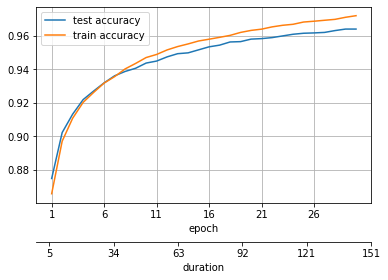


Train accuracy after 30 epochs: 0.9718833333333333
Test accuracy after 30 epochs: 0.9639
Duration of 30 epochs: 174


mlp a 2 hidden layers having 128 units with ReLU activation
minibatch sizes: 30, learning_rate=0.01


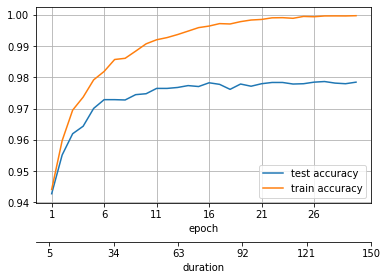


Train accuracy after 30 epochs: 0.9997666666666667
Test accuracy after 30 epochs: 0.9785
Duration of 30 epochs: 173


mlp a 2 hidden layers having 128 units with ReLU activation
minibatch sizes: 30, learning_rate=0.1


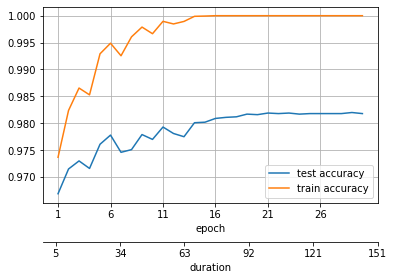


Train accuracy after 30 epochs: 1.0
Test accuracy after 30 epochs: 0.9818
Duration of 30 epochs: 174


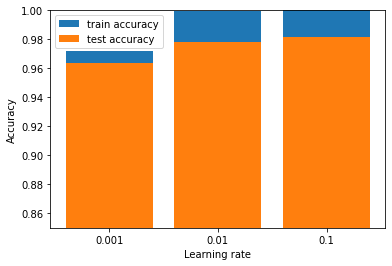

In [ ]:
tune_learning_rate()  # Figure14

Study performance using batch sizes of different scales (10, 100, 1000)

In [ ]:
# Study performance using batch sizes of different scales
def tune_batchsize():
    accuracies = []
    bsizes = [10, 100, 1000]  # Fig15, 16, 17
    for bsize in bsizes:
        print("\n\nmlp a 2 hidden layers having 128 units with ReLU activation")
        print(f"minibatch sizes: {bsize}, learning_rate={0.1}")
        mlp = MLP(ReLU, X_train.shape[1], [128, 128])
        accuracies.append(test_mlp_model(mlp, 30, bsize))
    plot_vs_accuracy(accuracies, bsizes, "Batch size")



mlp a 2 hidden layers having 128 units with ReLU activation
minibatch sizes: 10, learning_rate=0.1


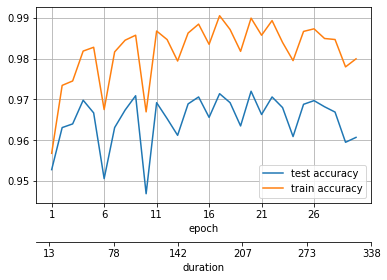


Train accuracy after 30 epochs: 0.9799333333333333
Test accuracy after 30 epochs: 0.9607
Duration of 30 epochs: 390


mlp a 2 hidden layers having 128 units with ReLU activation
minibatch sizes: 100, learning_rate=0.1


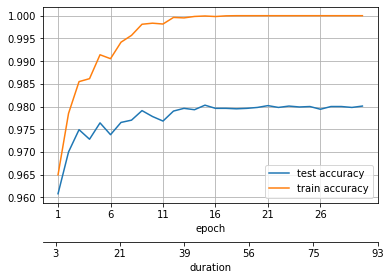


Train accuracy after 30 epochs: 1.0
Test accuracy after 30 epochs: 0.9801
Duration of 30 epochs: 107


mlp a 2 hidden layers having 128 units with ReLU activation
minibatch sizes: 1000, learning_rate=0.1


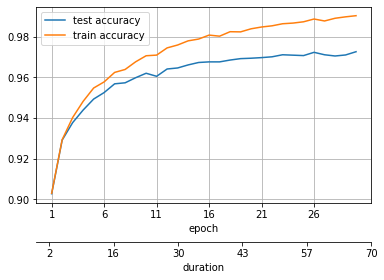


Train accuracy after 30 epochs: 0.9903333333333333
Test accuracy after 30 epochs: 0.9726
Duration of 30 epochs: 81


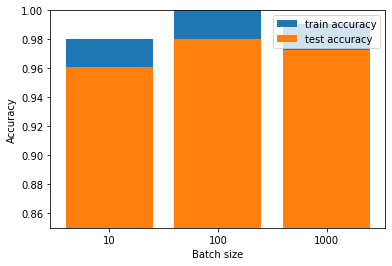

In [ ]:
tune_batchsize()  # Figure18

Part 3.1 experiments

In [ ]:
def tune_hyperparams(hidden_layers):
    """Find optimum learning rate and batch size for a model.
    We only run 20 epochs to also check for faster convergence."""
    print("Tuning hyperparameters")
    bsizes = [30, 50, 70, 100]
    lrs = [0.01, 0.1]
    accs = []
    pairs = []
    for bsize in bsizes:
        for lr in lrs:
            pairs.append((lr, bsize))
            mlp = MLP(ReLU, X_train.shape[1], hidden_layers, lr=lr)
            _, test_acc = test_mlp_model(mlp, 10, bsize, plot=False)
            accs.append(test_acc)
            print(f"test accuracy: {test_acc}, learning rate: {lr}, batchsize: {bsize}")

    max_index = accs.index(max(accs))
    lr, bs = pairs[max_index]
    print("\n--------------------------------------------------------------\n")
    print(f"Best hyperparameter: learning rate: {lr}, minibatch size: {bs}")
    print("\n--------------------------------------------------------------\n")
    return lr, bs



mlp with no hidden layer, directly map input to output
Tuning hyperparameters




Train accuracy after 10 epochs: 0.92845
Test accuracy after 10 epochs: 0.9252
Duration of 10 epochs: 9
test accuracy: 0.9252, learning rate: 0.01, batchsize: 30




Train accuracy after 10 epochs: 0.9138833333333334
Test accuracy after 10 epochs: 0.9062
Duration of 10 epochs: 9
test accuracy: 0.9062, learning rate: 0.1, batchsize: 30




Train accuracy after 10 epochs: 0.9254
Test accuracy after 10 epochs: 0.9211
Duration of 10 epochs: 14
test accuracy: 0.9211, learning rate: 0.01, batchsize: 50




Train accuracy after 10 epochs: 0.9266666666666666
Test accuracy after 10 epochs: 0.9197
Duration of 10 epochs: 14
test accuracy: 0.9197, learning rate: 0.1, batchsize: 50




Train accuracy after 10 epochs: 0.9237666666666666
Test accuracy after 10 epochs: 0.9203
Duration of 10 epochs: 12
test accuracy: 0.9203, learning rate: 0.01, batchsize: 70




Train accuracy after 10 epochs: 0.91645
Test accuracy after 10 epochs: 0.9098
Duration of 10 epochs: 13
test accuracy: 0.9098, learning rate: 0.1, batchsize: 70




Train accuracy after 10 epochs: 0.92225
Test accuracy after 10 epochs: 0.9211
Duration of 10 epochs: 12
test accuracy: 0.9211, learning rate: 0.01, batchsize: 100




Train accuracy after 10 epochs: 0.9283833333333333
Test accuracy after 10 epochs: 0.922
Duration of 10 epochs: 12
test accuracy: 0.922, learning rate: 0.1, batchsize: 100

--------------------------------------------------------------

Best hyperparameter: learning rate: 0.01, minibatch size: 30

--------------------------------------------------------------

minibatch sizes: 30, learning_rate: 0.01



epoch 1 - train: 0.9070666666666667, test: 0.9104, duration: 1
epoch 2 - train: 0.91605, test: 0.9146, duration: 2
epoch 3 - train: 0.9192, test: 0.9179, duration: 3
epoch 4 - train: 0.9223, test: 0.9214, duration: 4
epoch 5 - train: 0.9248333333333333, test: 0.9219, duration: 5
epoch 6 - train: 0.9247333333333333, test: 0.92, duration: 6
epoch 7 - train: 0.9264, test: 0.9232, duration: 7
epoch 8 - train: 0.9266833333333333, test: 0.9246, duration: 8
epoch 9 - train: 0.9294166666666667, test: 0.9224, duration: 9
epoch 10 - train: 0.9288833333333333, test: 0.9234, duration: 10
epoch 11 - train: 0.9299833333333334, test: 0.9247, duration: 11
epoch 12 - train: 0.9286666666666666, test: 0.924, duration: 11
epoch 13 - train: 0.93035, test: 0.9236, duration: 12
epoch 14 - train: 0.9300166666666667, test: 0.9229, duration: 13
epoch 15 - train: 0.9308166666666666, test: 0.9237, duration: 14
epoch 16 - train: 0.9304833333333333, test: 0.924, duration: 15
epoch 17 - train: 0.9315166666666667, t

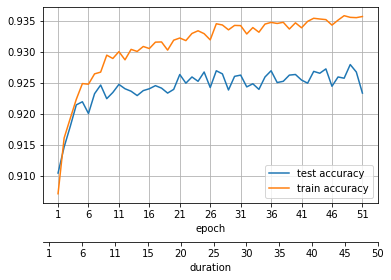


Train accuracy after 51 epochs: 0.93565
Test accuracy after 51 epochs: 0.9233
Duration of 51 epochs: 50


(0.93565, 0.9233)

In [26]:
# Part3.1
# ---------------------------------------------------------------------
print("\n\nmlp with no hidden layer, directly map input to output")
lr, bs = tune_hyperparams([])
print(f"minibatch sizes: {bs}, learning_rate: {lr}")
mlp = MLP(ReLU, X_train.shape[1], [], lr=lr)
test_mlp_model(mlp, 51, bs, print_lists=True)  



mlp a sigle hidden layer having 128 units with ReLU activation
Tuning hyperparameters




Train accuracy after 10 epochs: 0.9863
Test accuracy after 10 epochs: 0.9739
Duration of 10 epochs: 49
test accuracy: 0.9739, learning rate: 0.01, batchsize: 30




Train accuracy after 10 epochs: 0.9992166666666666
Test accuracy after 10 epochs: 0.9788
Duration of 10 epochs: 48
test accuracy: 0.9788, learning rate: 0.1, batchsize: 30




Train accuracy after 10 epochs: 0.9779
Test accuracy after 10 epochs: 0.9698
Duration of 10 epochs: 38
test accuracy: 0.9698, learning rate: 0.01, batchsize: 50




Train accuracy after 10 epochs: 0.9985
Test accuracy after 10 epochs: 0.9785
Duration of 10 epochs: 38
test accuracy: 0.9785, learning rate: 0.1, batchsize: 50




Train accuracy after 10 epochs: 0.9729166666666667
Test accuracy after 10 epochs: 0.9655
Duration of 10 epochs: 34
test accuracy: 0.9655, learning rate: 0.01, batchsize: 70




Train accuracy after 10 epochs: 0.99815
Test accuracy after 10 epochs: 0.979
Duration of 10 epochs: 34
test accuracy: 0.979, learning rate: 0.1, batchsize: 70




Train accuracy after 10 epochs: 0.9661333333333333
Test accuracy after 10 epochs: 0.9639
Duration of 10 epochs: 30
test accuracy: 0.9639, learning rate: 0.01, batchsize: 100




Train accuracy after 10 epochs: 0.9968
Test accuracy after 10 epochs: 0.9782
Duration of 10 epochs: 30
test accuracy: 0.9782, learning rate: 0.1, batchsize: 100

--------------------------------------------------------------

Best hyperparameter: learning rate: 0.1, minibatch size: 70

--------------------------------------------------------------

minibatch sizes: 70, learning_rate: 0.1



epoch 1 - train: 0.9636, test: 0.9577, duration: 3
epoch 2 - train: 0.9771333333333333, test: 0.9686, duration: 6
epoch 3 - train: 0.9851166666666666, test: 0.9756, duration: 10
epoch 4 - train: 0.98785, test: 0.9754, duration: 13
epoch 5 - train: 0.9906333333333334, test: 0.9769, duration: 17
epoch 6 - train: 0.9925833333333334, test: 0.9774, duration: 20
epoch 7 - train: 0.9937333333333334, test: 0.9775, duration: 24
epoch 8 - train: 0.99595, test: 0.9782, duration: 27
epoch 9 - train: 0.9975, test: 0.979, duration: 31
epoch 10 - train: 0.9975833333333334, test: 0.9759, duration: 34
epoch 11 - train: 0.99855, test: 0.9794, duration: 38
epoch 12 - train: 0.9989833333333333, test: 0.979, duration: 41
epoch 13 - train: 0.9994166666666666, test: 0.9801, duration: 44
epoch 14 - train: 0.9994833333333333, test: 0.9796, duration: 48
epoch 15 - train: 0.9997333333333334, test: 0.9801, duration: 51
epoch 16 - train: 0.9997833333333334, test: 0.9799, duration: 55
epoch 17 - train: 0.999933333

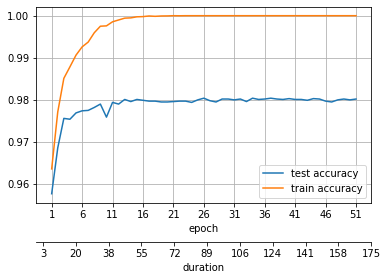


Train accuracy after 51 epochs: 1.0
Test accuracy after 51 epochs: 0.9802
Duration of 51 epochs: 175


(1.0, 0.9802)

In [27]:
print("\n\nmlp a sigle hidden layer having 128 units with ReLU activation")
lr, bs = tune_hyperparams([128])
print(f"minibatch sizes: {bs}, learning_rate: {lr}")
mlp = MLP(ReLU, X_train.shape[1], [128], lr=lr)
test_mlp_model(mlp, 51, bs, print_lists=True) 



mlp a 2 hidden layers having 128 units with ReLU activation
Tuning hyperparameters




Train accuracy after 10 epochs: 0.9868166666666667
Test accuracy after 10 epochs: 0.9725
Duration of 10 epochs: 59
test accuracy: 0.9725, learning rate: 0.01, batchsize: 30




Train accuracy after 10 epochs: 0.9971333333333333
Test accuracy after 10 epochs: 0.9796
Duration of 10 epochs: 58
test accuracy: 0.9796, learning rate: 0.1, batchsize: 30




Train accuracy after 10 epochs: 0.9839333333333333
Test accuracy after 10 epochs: 0.9712
Duration of 10 epochs: 46
test accuracy: 0.9712, learning rate: 0.01, batchsize: 50




Train accuracy after 10 epochs: 0.9991166666666667
Test accuracy after 10 epochs: 0.9809
Duration of 10 epochs: 46
test accuracy: 0.9809, learning rate: 0.1, batchsize: 50




Train accuracy after 10 epochs: 0.9766166666666667
Test accuracy after 10 epochs: 0.9666
Duration of 10 epochs: 41
test accuracy: 0.9666, learning rate: 0.01, batchsize: 70




Train accuracy after 10 epochs: 0.9991666666666666
Test accuracy after 10 epochs: 0.9807
Duration of 10 epochs: 41
test accuracy: 0.9807, learning rate: 0.1, batchsize: 70




Train accuracy after 10 epochs: 0.96995
Test accuracy after 10 epochs: 0.9635
Duration of 10 epochs: 35
test accuracy: 0.9635, learning rate: 0.01, batchsize: 100




Train accuracy after 10 epochs: 0.9979833333333333
Test accuracy after 10 epochs: 0.98
Duration of 10 epochs: 35
test accuracy: 0.98, learning rate: 0.1, batchsize: 100

--------------------------------------------------------------

Best hyperparameter: learning rate: 0.1, minibatch size: 50

--------------------------------------------------------------

minibatch sizes: 50, learning_rate: 0.1



epoch 1 - train: 0.9691833333333333, test: 0.9606, duration: 4
epoch 2 - train: 0.9823333333333333, test: 0.9714, duration: 8
epoch 3 - train: 0.98275, test: 0.9726, duration: 13
epoch 4 - train: 0.99105, test: 0.9755, duration: 17
epoch 5 - train: 0.9917333333333334, test: 0.9775, duration: 22
epoch 6 - train: 0.9878833333333333, test: 0.9721, duration: 27
epoch 7 - train: 0.9959333333333333, test: 0.9777, duration: 31
epoch 8 - train: 0.9975, test: 0.9799, duration: 36
epoch 9 - train: 0.9989, test: 0.9817, duration: 41
epoch 10 - train: 0.9997, test: 0.9811, duration: 45
epoch 11 - train: 0.9998833333333333, test: 0.9817, duration: 50
epoch 12 - train: 0.99985, test: 0.9814, duration: 55
epoch 13 - train: 0.9999666666666667, test: 0.9811, duration: 59
epoch 14 - train: 1.0, test: 0.9818, duration: 64
epoch 15 - train: 0.9991666666666666, test: 0.9816, duration: 68
epoch 16 - train: 1.0, test: 0.9817, duration: 73
epoch 17 - train: 1.0, test: 0.9817, duration: 77
epoch 18 - train: 1

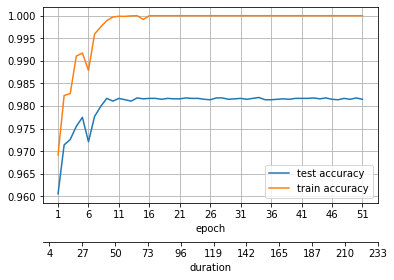


Train accuracy after 51 epochs: 1.0
Test accuracy after 51 epochs: 0.9815
Duration of 51 epochs: 233


(1.0, 0.9815)

In [28]:
print("\n\nmlp a 2 hidden layers having 128 units with ReLU activation")
lr, bs = tune_hyperparams([128, 128])
print(f"minibatch sizes: {bs}, learning_rate: {lr}")
mlp = MLP(ReLU, X_train.shape[1], [128, 128], lr=lr)
test_mlp_model(mlp, 51, bs, print_lists=True)  

Study the effect of network depth on accuracy

MLP depth: 0




Train accuracy after 20 epochs: 0.8986333333333333
Test accuracy after 20 epochs: 0.8909
Duration of 20 epochs: 20
MLP depth: 1




Train accuracy after 20 epochs: 1.0
Test accuracy after 20 epochs: 0.9806
Duration of 20 epochs: 100
MLP depth: 2




Train accuracy after 20 epochs: 1.0
Test accuracy after 20 epochs: 0.9826
Duration of 20 epochs: 120
MLP depth: 3




Train accuracy after 20 epochs: 0.99935
Test accuracy after 20 epochs: 0.9816
Duration of 20 epochs: 138
MLP depth: 4




Train accuracy after 20 epochs: 0.99875
Test accuracy after 20 epochs: 0.9789
Duration of 20 epochs: 158
MLP depth: 5


... (6 outputs left out)



Train accuracy after 20 epochs: 0.9979666666666667
Test accuracy after 20 epochs: 0.9807
Duration of 20 epochs: 292
MLP depth: 12




Train accuracy after 20 epochs: 0.9933666666666666
Test accuracy after 20 epochs: 0.9753
Duration of 20 epochs: 310
MLP depth: 13




Train accuracy after 20 epochs: 0.99655
Test accuracy after 20 epochs: 0.9789
Duration of 20 epochs: 330
MLP depth: 14




Train accuracy after 20 epochs: 0.99585
Test accuracy after 20 epochs: 0.9791
Duration of 20 epochs: 352


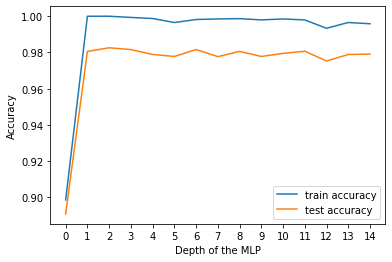

In [32]:
# Study the effect of depth on performance
def test_depth_accuracy(depth, epochs):
    accuracies = []
    depths = range(depth)
    for depth in depths:
        print(f"MLP depth: {depth}")
        mlp = MLP(ReLU, X_train.shape[1], [128] * depth)
        accuracies.append(test_mlp_model(mlp, epochs, 30, plot=False))
    plot_depth_accuracy(accuracies, depths)


test_depth_accuracy(15, 20)  

Study the effect of increasing the hidden layers on performance



Train accuracy after 20 epochs: 0.3036
Test accuracy after 20 epochs: 0.3025
Duration of 20 epochs: 21




Train accuracy after 20 epochs: 0.9779833333333333
Test accuracy after 20 epochs: 0.9597
Duration of 20 epochs: 41




Train accuracy after 20 epochs: 0.9931166666666666
Test accuracy after 20 epochs: 0.9669
Duration of 20 epochs: 48




Train accuracy after 20 epochs: 0.9999833333333333
Test accuracy after 20 epochs: 0.9789
Duration of 20 epochs: 67




Train accuracy after 20 epochs: 1.0
Test accuracy after 20 epochs: 0.9796
Duration of 20 epochs: 75




Train accuracy after 20 epochs: 1.0
Test accuracy after 20 epochs: 0.9796
Duration of 20 epochs: 85




Train accuracy after 20 epochs: 1.0
Test accuracy after 20 epochs: 0.981
Duration of 20 epochs: 99




Train accuracy after 20 epochs: 1.0
Test accuracy after 20 epochs: 0.9809
Duration of 20 epochs: 111




Train accuracy after 20 epochs: 1.0
Test accuracy after 20 epochs: 0.9815
Duration of 20 epochs: 121




Train accuracy after 20 epochs: 1.0
Test accuracy after 20 epochs: 0.9831
Duration of 20 epochs: 133




Train accuracy after 20 epochs: 1.0
Test accuracy after 20 epochs: 0.9825
Duration of 20 epochs: 143


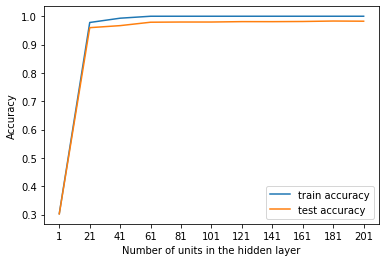

In [33]:
def test_units_accuracy(units, steps, epochs):
    accuracies = []
    units = range(1, units, steps)
    for unit in units:
        mlp = MLP(ReLU, X_train.shape[1], [unit])
        accuracies.append(test_mlp_model(mlp, epochs, 30, plot=False))
    plot_unit_accuracy(accuracies, units)


test_units_accuracy(220, 20, 20)  # Figure5

Part 3.2



mlp a 2 hidden layers having 128 units with ReLU activation



epoch 1 - train: 0.9680166666666666, test: 0.9609, duration: 6
epoch 2 - train: 0.9826666666666667, test: 0.973, duration: 12
epoch 3 - train: 0.987, test: 0.9725, duration: 18
epoch 4 - train: 0.9907, test: 0.9795, duration: 24
epoch 5 - train: 0.9891, test: 0.9755, duration: 30
epoch 6 - train: 0.9943166666666666, test: 0.977, duration: 37
epoch 7 - train: 0.9943166666666666, test: 0.976, duration: 43
epoch 8 - train: 0.9962833333333333, test: 0.9804, duration: 48
epoch 9 - train: 0.9938833333333333, test: 0.9741, duration: 54
epoch 10 - train: 0.9972833333333333, test: 0.979, duration: 60
epoch 11 - train: 0.9988, test: 0.9804, duration: 67
epoch 12 - train: 0.99895, test: 0.9806, duration: 73
epoch 13 - train: 0.9997, test: 0.9819, duration: 79
epoch 14 - train: 0.99965, test: 0.9828, duration: 85
epoch 15 - train: 0.9999833333333333, test: 0.9823, duration: 91
epoch 16 - train: 1.0, test: 0.9832, duration: 97
epoch 17 - train: 1.0, test: 0.9831, duration: 103
epoch 18 - train: 1.

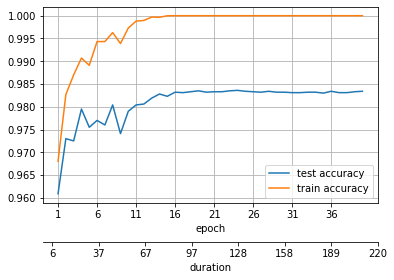


Train accuracy after 40 epochs: 1.0
Test accuracy after 40 epochs: 0.9834
Duration of 40 epochs: 244


In [34]:
accuracies = []

print("\n\nmlp a 2 hidden layers having 128 units with ReLU activation")
mlp = MLP(ReLU, X_train.shape[1], [128, 128])
accuracies.append(test_mlp_model(mlp, 40, 30, print_lists=True))  # Figure6



mlp a 2 hidden layers having 128 units with LeakyRelu activation



epoch 1 - train: 0.9681, test: 0.9607, duration: 6
epoch 2 - train: 0.98395, test: 0.9751, duration: 12
epoch 3 - train: 0.9876, test: 0.9756, duration: 19
epoch 4 - train: 0.9874666666666667, test: 0.9717, duration: 25
epoch 5 - train: 0.9934666666666667, test: 0.9769, duration: 31
epoch 6 - train: 0.9940666666666667, test: 0.9783, duration: 38
epoch 7 - train: 0.9932, test: 0.9751, duration: 44
epoch 8 - train: 0.9965166666666667, test: 0.9789, duration: 51
epoch 9 - train: 0.9980666666666667, test: 0.978, duration: 57
epoch 10 - train: 0.99855, test: 0.9799, duration: 64
epoch 11 - train: 0.9991833333333333, test: 0.9808, duration: 70
epoch 12 - train: 0.9992666666666666, test: 0.9797, duration: 77
epoch 13 - train: 0.9996666666666667, test: 0.9807, duration: 83
epoch 14 - train: 0.99995, test: 0.9811, duration: 90
epoch 15 - train: 1.0, test: 0.9817, duration: 97
epoch 16 - train: 1.0, test: 0.982, duration: 103
epoch 17 - train: 1.0, test: 0.982, duration: 110
epoch 18 - train: 1

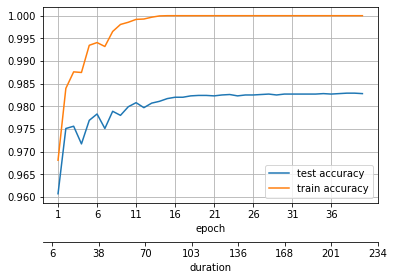


Train accuracy after 40 epochs: 1.0
Test accuracy after 40 epochs: 0.9828
Duration of 40 epochs: 260


In [35]:
print("\n\nmlp a 2 hidden layers having 128 units with LeakyRelu activation")
mlp = MLP(LeakyRelu, X_train.shape[1], [128, 128])
accuracies.append(test_mlp_model(mlp, 40, 30, print_lists=True))  # Figure19



mlp a 2 hidden layers having 128 units with TanH activation



epoch 1 - train: 0.9712666666666666, test: 0.9643, duration: 9
epoch 2 - train: 0.9728666666666667, test: 0.9617, duration: 19
epoch 3 - train: 0.98685, test: 0.9716, duration: 30
epoch 4 - train: 0.9907666666666667, test: 0.9737, duration: 40
epoch 5 - train: 0.9951666666666666, test: 0.9752, duration: 50
epoch 6 - train: 0.9951333333333333, test: 0.9734, duration: 61
epoch 7 - train: 0.9962166666666666, test: 0.973, duration: 71
epoch 8 - train: 0.9977833333333334, test: 0.9756, duration: 81
epoch 9 - train: 0.99925, test: 0.9782, duration: 92
epoch 10 - train: 0.99995, test: 0.9773, duration: 102
epoch 11 - train: 0.9999666666666667, test: 0.9788, duration: 112
epoch 12 - train: 0.9999666666666667, test: 0.9775, duration: 122
epoch 13 - train: 0.9999833333333333, test: 0.9782, duration: 133
epoch 14 - train: 0.9999833333333333, test: 0.9785, duration: 143
epoch 15 - train: 0.9999833333333333, test: 0.9784, duration: 153
epoch 16 - train: 0.9999833333333333, test: 0.9783, duration: 

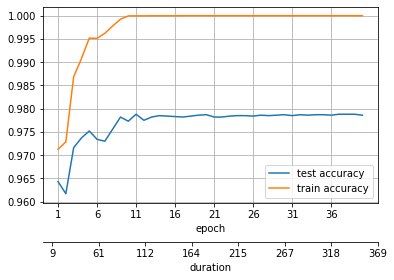


Train accuracy after 40 epochs: 1.0
Test accuracy after 40 epochs: 0.9786
Duration of 40 epochs: 411


In [36]:
print("\n\nmlp a 2 hidden layers having 128 units with TanH activation")
mlp = MLP(Tanh, X_train.shape[1], [128, 128])
accuracies.append(test_mlp_model(mlp, 40, 30, print_lists=True))  # Figure7



mlp a 2 hidden layers having 128 units with Sigmoid activation



epoch 1 - train: 0.9302833333333334, test: 0.9296, duration: 6
epoch 2 - train: 0.9523666666666667, test: 0.9472, duration: 12
epoch 3 - train: 0.9679333333333333, test: 0.9606, duration: 19
epoch 4 - train: 0.9740833333333333, test: 0.9646, duration: 26
epoch 5 - train: 0.9811666666666666, test: 0.9706, duration: 33
epoch 6 - train: 0.9845666666666667, test: 0.9717, duration: 39
epoch 7 - train: 0.9883, test: 0.9749, duration: 46
epoch 8 - train: 0.9899333333333333, test: 0.9745, duration: 53
epoch 9 - train: 0.9922, test: 0.9755, duration: 59
epoch 10 - train: 0.9931666666666666, test: 0.9756, duration: 66
epoch 11 - train: 0.99475, test: 0.9773, duration: 72
epoch 12 - train: 0.995, test: 0.9763, duration: 79
epoch 13 - train: 0.9969833333333333, test: 0.9775, duration: 85
epoch 14 - train: 0.9972833333333333, test: 0.977, duration: 92
epoch 15 - train: 0.9980666666666667, test: 0.977, duration: 99
epoch 16 - train: 0.9989166666666667, test: 0.9776, duration: 105
epoch 17 - train: 

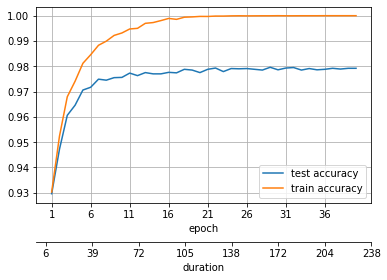


Train accuracy after 40 epochs: 1.0
Test accuracy after 40 epochs: 0.9792
Duration of 40 epochs: 264


In [37]:
print("\n\nmlp a 2 hidden layers having 128 units with Sigmoid activation")
mlp = MLP(Sig, X_train.shape[1], [128, 128])
accuracies.append(test_mlp_model(mlp, 40, 30, print_lists=True))  # Figure8

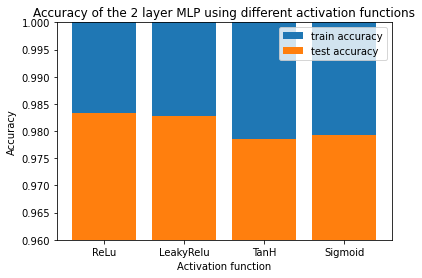

In [42]:
activations = ["ReLu", "LeakyRelu", "TanH", "Sigmoid"]
title = "Accuracy of the 2 layer MLP using different activation functions"
plot_activation_accuracy(accuracies, activations, title)  # Figure9